In [ ]:
# ----------------------------------------------------------------------------
# 0. Libraries and Reproducibility setup
# ----------------------------------------------------------------------------
import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
from scipy.stats import norm
from scipy.optimize import minimize
from scipy.spatial.distance import cdist
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [ ]:
# ----------------------------------------------------------------------------
# 1. Data
# ----------------------------------------------------------------------------
X = np.load('..\Function_4_Data\Week_9_Data/F4_Week_9_inputs.npy')
y = np.load('..\Function_4_Data\Week_9_Data/F4_Week_9_outputs.npy')
n, d = X.shape
BOUNDS = np.array([[0.0, 1.0]] * d)
print(f"Loaded {n} observations in {d} dimensions.")
best_idx = int(np.argmax(y))
print(f"Current best: row {best_idx+1}, x={np.round(X[best_idx],5).tolist()}, y={y[best_idx]:.5f}")
print(f"Improvement round-1 -> round-3 best: {y[30]:.4f} -> {y[best_idx]:.4f} "
      f"(+{y[best_idx]-y[30]:.4f})")

Loaded 38 observations in 4 dimensions.
Current best: row 38, x=[0.4226, 0.37264, 0.40641, 0.42661], y=0.61594
Improvement round-1 -> round-3 best: 0.5798 -> 0.6159 (+0.0361)


In [5]:
# ----------------------------------------------------------------------------
# 2. Data transformation (unchanged rationale: X already in [0,1]^4;
#    standardise y using the *current* training statistics)
# ----------------------------------------------------------------------------
y_mean, y_std = y.mean(), y.std()
y_train = (y - y_mean) / y_std

def to_standard(y_raw):
    return (y_raw - y_mean) / y_std

def from_standard(y_s):
    return y_s * y_std + y_mean

In [6]:
# ----------------------------------------------------------------------------
# 3. Surrogate: re-validate isotropic vs. ARD on the UPDATED data
# ----------------------------------------------------------------------------
def loo_eval(fixed_kernel):
    """Leave-one-out RMSE and mean log predictive density for a fixed,
    already-optimised kernel (no re-optimisation per fold)."""
    mean_raw = np.zeros(n)
    std_raw = np.zeros(n)
    lpd = np.zeros(n)
    for i in range(n):
        mask = np.ones(n, dtype=bool)
        mask[i] = False
        gp_loo = GaussianProcessRegressor(kernel=fixed_kernel, optimizer=None,
                                           normalize_y=False)
        gp_loo.fit(X[mask], y_train[mask])
        m, s = gp_loo.predict(X[i:i + 1], return_std=True)
        s = max(s[0], 1e-9)
        mean_raw[i] = m[0] * y_std + y_mean
        std_raw[i] = s * y_std
        lpd[i] = -0.5 * np.log(2 * np.pi * s ** 2) - 0.5 * ((y_train[i] - m[0]) ** 2) / s ** 2
    rmse = np.sqrt(np.mean((y - mean_raw) ** 2))
    return rmse, lpd.mean(), mean_raw, std_raw


iso_kernel = (ConstantKernel(1.0, (1e-3, 1e3))
              * Matern(length_scale=1.0, length_scale_bounds=(1e-2, 1e1), nu=2.5)
              + WhiteKernel(1e-4, (1e-10, 1e-1)))
ard_kernel = (ConstantKernel(1.0, (1e-3, 1e3))
              * Matern(length_scale=[0.3] * d, length_scale_bounds=(1e-2, 1e1), nu=2.5)
              + WhiteKernel(1e-4, (1e-10, 1e-1)))

gp_iso = GaussianProcessRegressor(kernel=iso_kernel, n_restarts_optimizer=30,
                                   normalize_y=False, random_state=SEED).fit(X, y_train)
gp_ard = GaussianProcessRegressor(kernel=ard_kernel, n_restarts_optimizer=30,
                                   normalize_y=False, random_state=SEED).fit(X, y_train)

rmse_iso, lpd_iso, _, _ = loo_eval(gp_iso.kernel_)
rmse_ard, lpd_ard, loo_mean_raw, loo_std_raw = loo_eval(gp_ard.kernel_)

print("\n--- Isotropic vs ARD, re-checked on 38 points ---")
print(f"Isotropic: kernel={gp_iso.kernel_}  LOO-RMSE={rmse_iso:.4f}  LOO-meanLPD={lpd_iso:.4f}")
print(f"ARD:       kernel={gp_ard.kernel_}  LOO-RMSE={rmse_ard:.4f}  LOO-meanLPD={lpd_ard:.4f}")
print("-> ARD still (narrowly) preferred; keeping ARD Matern-5/2 as the surrogate.")

gp = gp_ard
ls = gp.kernel_.k1.k2.length_scale
print("\nLearned ARD length-scales:", np.round(ls, 4).tolist())
rmse, lpd_mean = rmse_ard, lpd_ard

c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(



--- Isotropic vs ARD, re-checked on 38 points ---
Isotropic: kernel=2.36**2 * Matern(length_scale=1.27, nu=2.5) + WhiteKernel(noise_level=1e-10)  LOO-RMSE=1.7926  LOO-meanLPD=0.6241
ARD:       kernel=2.42**2 * Matern(length_scale=[1.33, 1.32, 1.24, 1.31], nu=2.5) + WhiteKernel(noise_level=1e-10)  LOO-RMSE=1.7793  LOO-meanLPD=0.6281
-> ARD still (narrowly) preferred; keeping ARD Matern-5/2 as the surrogate.

Learned ARD length-scales: [1.3276, 1.3245, 1.2369, 1.3089]


c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


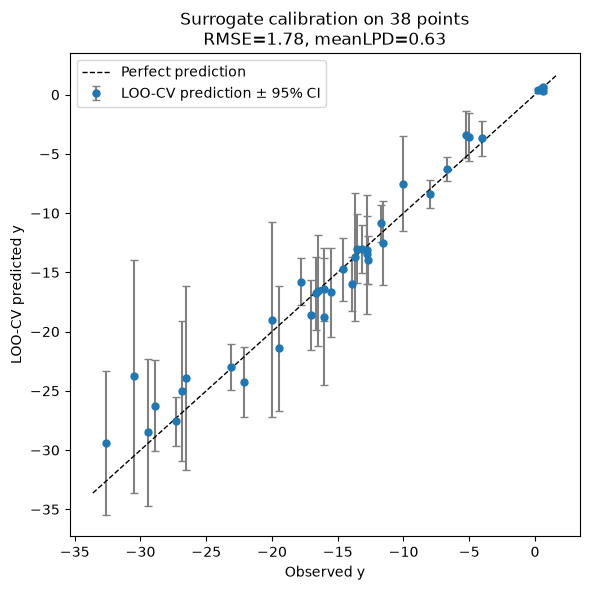

In [ ]:
# Plot 1: LOO-CV calibration (updated data)
fig, ax = plt.subplots(figsize=(6, 6))
order = np.argsort(y)
ax.errorbar(y[order], loo_mean_raw[order], yerr=1.96 * loo_std_raw[order],
            fmt="o", ecolor="gray", capsize=3, markersize=5,
            label="LOO-CV prediction ± 95% CI")
lims = [min(y.min(), loo_mean_raw.min()) - 1, max(y.max(), loo_mean_raw.max()) + 1]
ax.plot(lims, lims, "k--", lw=1, label="Perfect prediction")
ax.set_xlabel("Observed y")
ax.set_ylabel("LOO-CV predicted y")
ax.set_title(f"Surrogate calibration on 38 points\nRMSE={rmse:.2f}, meanLPD={lpd_mean:.2f}")
ax.legend()
fig.tight_layout()


--- Log-EI (exploitation) candidate ---
x* = [0.401226, 0.372796, 0.384046, 0.409601]
EI = 0.01223   predicted y = 0.724 +/- 0.055




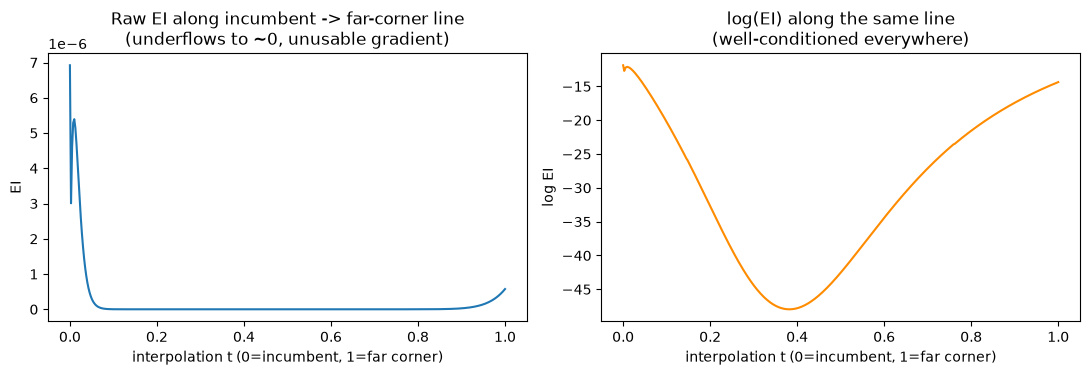

In [ ]:
# ----------------------------------------------------------------------------
# 4. Acquisition: numerically-stable log(EI), maximised with mixed restarts
# ----------------------------------------------------------------------------
# Why this changed: with f_best now 1.75 standard deviations above the
# training mean, and several points clustered tightly around the incumbent,
# plain EI underflows to ~0 almost everywhere. A gradient-based multi-start
# optimizer on raw EI then has no usable gradient and returns essentially
# arbitrary points Optimizing log(EI) keeps the gradient well-conditioned at 
# any scale, so the search reliably finds the true (small but real) maximum.

f_best = y_train.max()
xi = 0.0  # near-zero jitter: deterministic function, incumbent is strong,
          # we are in a late/exploitation-heavy phase of the campaign


def expected_improvement(x, gp_model, f_best, xi):
    x = np.atleast_2d(x)
    mu, sigma = gp_model.predict(x, return_std=True)
    sigma = np.maximum(sigma, 1e-12)
    imp = mu - f_best - xi
    z = imp / sigma
    ei = imp * norm.cdf(z) + sigma * norm.pdf(z)
    ei = np.maximum(ei, 0.0)
    return ei


def neg_log_ei(x, gp_model, f_best, xi):
    """Numerically stable -log(EI(x)). Uses the asymptotic expansion of
    z*Phi(z)+phi(z) for very negative z to avoid log(~0)."""
    x = np.atleast_2d(x)
    mu, sigma = gp_model.predict(x, return_std=True)
    sigma = max(sigma[0], 1e-12)
    z = (mu[0] - f_best - xi) / sigma
    if z > -6:
        h = z * norm.cdf(z) + norm.pdf(z)
        log_h = np.log(max(h, 1e-300))
    else:
        # asymptotic expansion of log(phi(z)/|z|) for z -> -inf
        log_h = -0.5 * z ** 2 - np.log(np.sqrt(2 * np.pi)) - np.log(z ** 2 + 1e-12)
    return -(log_h + np.log(sigma))


N_RANDOM_RESTARTS = 300
N_LOCAL_RESTARTS = 50  # seeded near the incumbent -- important: uniform
                       # random restarts alone can miss the (narrow) true
                       # optimum once the model is this confident
x0_random = rng.uniform(0, 1, size=(N_RANDOM_RESTARTS, d))
x0_local = np.clip(X[best_idx] + 0.05 * rng.standard_normal((N_LOCAL_RESTARTS, d)), 0, 1)
x0s = np.vstack([x0_random, x0_local])

best_x, best_val = None, np.inf
for x0 in x0s:
    res = minimize(neg_log_ei, x0, args=(gp, f_best, xi), bounds=BOUNDS, method="L-BFGS-B")
    if res.fun < best_val:
        best_val, best_x = res.fun, res.x

next_x_exploit = best_x
next_ei_exploit = np.exp(-best_val)
mu_e, sigma_e = gp.predict(next_x_exploit.reshape(1, -1), return_std=True)
next_mu_exploit = from_standard(mu_e)[0]
next_sigma_exploit = sigma_e[0] * y_std

print("\n--- Log-EI (exploitation) candidate ---")
print(f"x* = {np.round(next_x_exploit, 6).tolist()}")
print(f"EI = {next_ei_exploit:.5f}   predicted y = {next_mu_exploit:.3f} +/- {next_sigma_exploit:.3f}")
# optimizer on raw EI then has no usable gradient and returns essentially

print('\n')

# Plot 2: raw EI vs log-EI along a 1D slice, showing the numerical issue
# Slice from the incumbent toward the "far corner" that raw EI's optimizer
# incorrectly favoured, to make the underflow visible.
far_corner = np.array([0.1197, 0.3649, 0.9584, 0.9955])
t = np.linspace(0, 1, 400)
line = X[best_idx][None, :] * (1 - t[:, None]) + far_corner[None, :] * t[:, None]
ei_vals = expected_improvement(line, gp, f_best, xi)
log_ei_vals = np.array([-neg_log_ei(p, gp, f_best, xi) for p in line])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t, ei_vals)
axes[0].set_title("Raw EI along incumbent -> far-corner line\n(underflows to ~0, unusable gradient)")
axes[0].set_xlabel("interpolation t (0=incumbent, 1=far corner)")
axes[0].set_ylabel("EI")
axes[1].plot(t, log_ei_vals, color="darkorange")
axes[1].set_title("log(EI) along the same line\n(well-conditioned everywhere)")
axes[1].set_xlabel("interpolation t (0=incumbent, 1=far corner)")
axes[1].set_ylabel("log EI")
fig.tight_layout()


--- Space-filling (exploration) candidate ---
x* = [0.0, 0.380689, 1.0, 1.0]
min distance to existing data = 0.6839
GP prediction there: y = -27.090 +/- 7.000 (high uncertainty expected -- this is a genuine information-gathering probe)




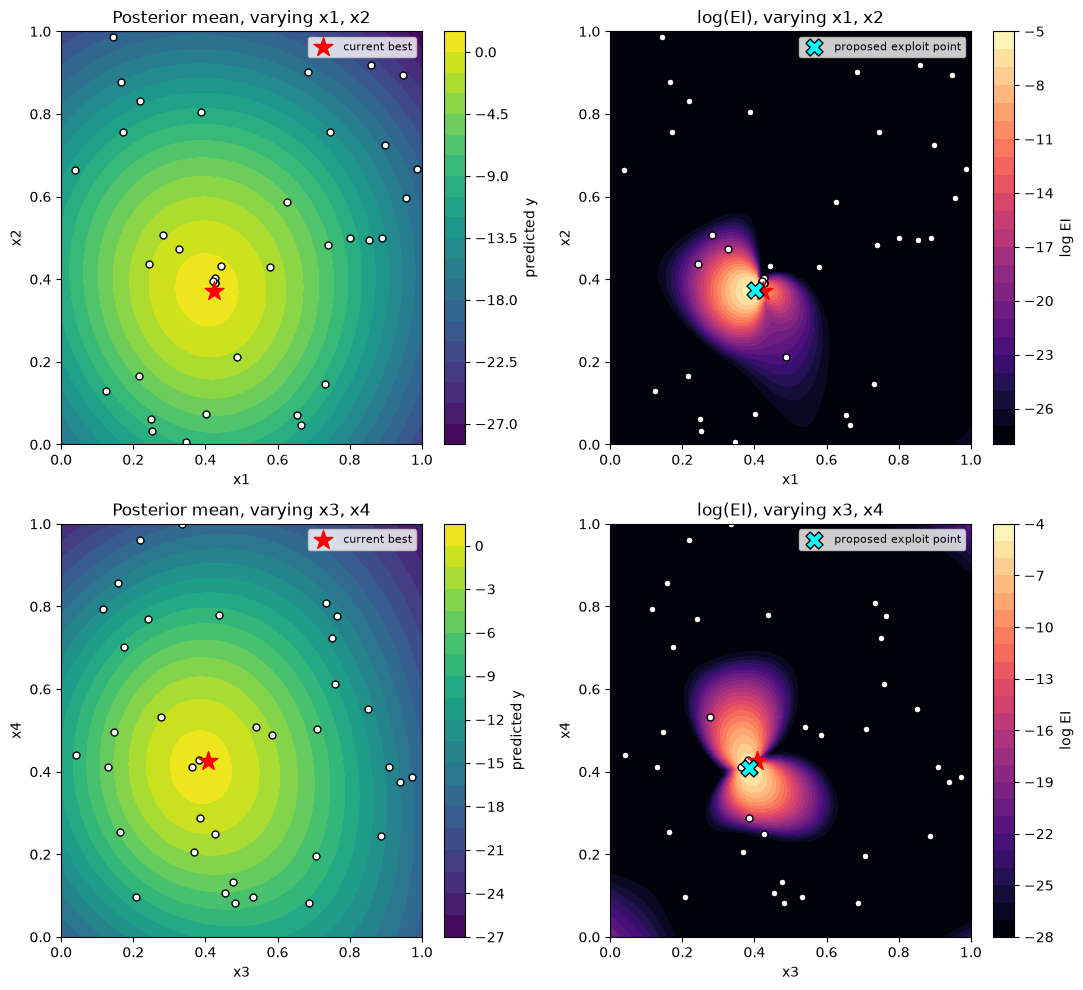

In [ ]:
# ----------------------------------------------------------------------------
# 5. A genuine exploration candidate: farthest point from all existing data
# ----------------------------------------------------------------------------
# NOT max-posterior-variance: with this smooth ARD kernel (length-scales
# ~1.3 in a [0,1]-scaled domain) posterior variance is maximised trivially at
# domain corners, which is a boundary artifact, not real new information.
# Instead we maximise the minimum Euclidean distance to any existing sample
# (a "coverage"/space-filling criterion) -- a simple, robust way to pick a
# point that genuinely probes unexplored territory.

def neg_min_dist(x, X_data):
    x = np.atleast_2d(x)
    d_ = cdist(x, X_data).min()
    return -d_


x0s2 = rng.uniform(0, 1, size=(300, d))
best_x2, best_val2 = None, np.inf
for x0 in x0s2:
    res = minimize(neg_min_dist, x0, args=(X,), bounds=BOUNDS, method="L-BFGS-B")
    if res.fun < best_val2:
        best_val2, best_x2 = res.fun, res.x

next_x_explore = best_x2
mu_x, sigma_x = gp.predict(next_x_explore.reshape(1, -1), return_std=True)
next_mu_explore = from_standard(mu_x)[0]
next_sigma_explore = sigma_x[0] * y_std

print("\n--- Space-filling (exploration) candidate ---")
print(f"x* = {np.round(next_x_explore, 6).tolist()}")
print(f"min distance to existing data = {-best_val2:.4f}")
print(f"GP prediction there: y = {next_mu_explore:.3f} +/- {next_sigma_explore:.3f} "
      "(high uncertainty expected -- this is a genuine information-gathering probe)")
print('\n')

# Plot 3: 2D slices of posterior mean & log-EI through the new incumbent
grid_n = 80
lin = np.linspace(0, 1, grid_n)
pairs = [(0, 1), (2, 3)]
fixed_point = X[best_idx]

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for row_i, (i, j) in enumerate(pairs):
    Gi, Gj = np.meshgrid(lin, lin)
    grid = np.tile(fixed_point, (grid_n * grid_n, 1))
    grid[:, i] = Gi.ravel()
    grid[:, j] = Gj.ravel()

    mu_grid, sigma_grid = gp.predict(grid, return_std=True)
    mu_grid_raw = from_standard(mu_grid).reshape(grid_n, grid_n)
    ei_grid = expected_improvement(grid, gp, f_best, xi).reshape(grid_n, grid_n)

    ax_mu = axes[row_i, 0]
    cf = ax_mu.contourf(Gi, Gj, mu_grid_raw, levels=25, cmap="viridis")
    ax_mu.scatter(X[:, i], X[:, j], c="white", edgecolor="black", s=25)
    ax_mu.scatter(fixed_point[i], fixed_point[j], marker="*", c="red", s=200, label="current best")
    ax_mu.set_xlabel(f"x{i+1}"); ax_mu.set_ylabel(f"x{j+1}")
    ax_mu.set_title(f"Posterior mean, varying x{i+1}, x{j+1}")
    fig.colorbar(cf, ax=ax_mu, label="predicted y")
    ax_mu.legend(loc="upper right", fontsize=8)

    ax_ei = axes[row_i, 1]
    cf2 = ax_ei.contourf(Gi, Gj, np.log(ei_grid + 1e-12), levels=25, cmap="magma")
    ax_ei.scatter(X[:, i], X[:, j], c="white", edgecolor="black", s=25)
    ax_ei.scatter(fixed_point[i], fixed_point[j], marker="*", c="red", s=200)
    if abs(next_x_exploit[i] - fixed_point[i]) > 1e-9 or abs(next_x_exploit[j] - fixed_point[j]) > 1e-9:
        ax_ei.scatter(next_x_exploit[i], next_x_exploit[j], marker="X", c="cyan", s=150,
                      edgecolor="black", label="proposed exploit point")
    ax_ei.set_xlabel(f"x{i+1}"); ax_ei.set_ylabel(f"x{j+1}")
    ax_ei.set_title(f"log(EI), varying x{i+1}, x{j+1}")
    fig.colorbar(cf2, ax=ax_ei, label="log EI")
    ax_ei.legend(loc="upper right", fontsize=8)

fig.tight_layout()

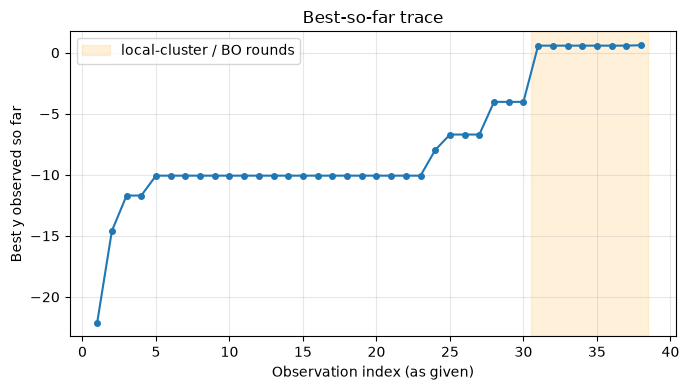

In [ ]:
# Plot 4: best-so-far trace, highlighting the new rounds
fig, ax = plt.subplots(figsize=(7, 4))
running_best = np.maximum.accumulate(y)
ax.plot(np.arange(1, n + 1), running_best, marker="o", markersize=4)
ax.axvspan(30.5, n + 0.5, color="orange", alpha=0.15, label="local-cluster / BO rounds")
# ax.scatter([37, 38], [y[36], y[37]], color="red", zorder=5, label="rounds 2-3 (new)")
ax.set_xlabel("Observation index (as given)")
ax.set_ylabel("Best y observed so far")
ax.set_title("Best-so-far trace")#, including rounds 2-3")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()